# Практическое задание 3. Какие партии проверить перед отгрузкой?

**Дисциплина «ИИ и машинное обучение»** · НИУ ВШЭ, Высшая школа бизнеса

Магистратура «Бизнес-аналитика и цифровые решения в финансах»

---

Каждый день к отгрузке готовы 60 партий продукции; в некоторых есть скрытый
дефект одного из трёх типов. Лаборатория может проверить до 24 партий в день
одним из трёх методов. Нужно каждый день решить, какие партии проверить,
каким методом и сколько проверок провести, опираясь на прогнозы 12 готовых
моделей, и обосновать выбор метриками и деньгами.

Что требуется, как считается экономия J и как ставится оценка — в тексте
задания: https://github.com/Rimest/ml_ai_course_gsb_hse/blob/main/homeworks/hw3_quality_control/README.md

Здесь справочник данных и функций, загрузка, готовые инструменты, место под
решение и готовая сборка файла сдачи.

**Как работать.** Выполняйте ячейки сверху вниз. Данные лежат в папке задания
репозитория курса рядом с этим ноутбуком. Ячейка загрузки находит их рядом
с ноутбуком, а если их нет — скачивает из этой папки.
Ячейки с расчётами, графиками и выводами добавляйте в раздел «Решение»
в любом порядке и количестве.

**Что сдать:** боту курса — этот ноутбук `ФАМИЛИЯ_ИО.ipynb` с выполненными
ячейками и файл `ФАМИЛИЯ_ИО_actions.csv` с решениями по партиям закрытого теста.

## Преамбула

Впишите фамилию с инициалами и выполните ячейку. Если в вашем решении есть
случайность, используйте `SEED` везде, где есть параметр `random_state`:
ноутбук должен при повторном запуске сверху вниз давать тот же файл сдачи.

In [ ]:
## ── кто сдаёт и воспроизводимость ──────────────────────────────────
import random

STUDENT_NAME = "ФАМИЛИЯ_ИО"  # впишите фамилию и инициалы, например "ИВАНОВ_ИИ"
SEED = 42
random.seed(SEED)  # стандартный модуль random; numpy получает SEED при загрузке ниже

## Как связаны прогнозы и решение

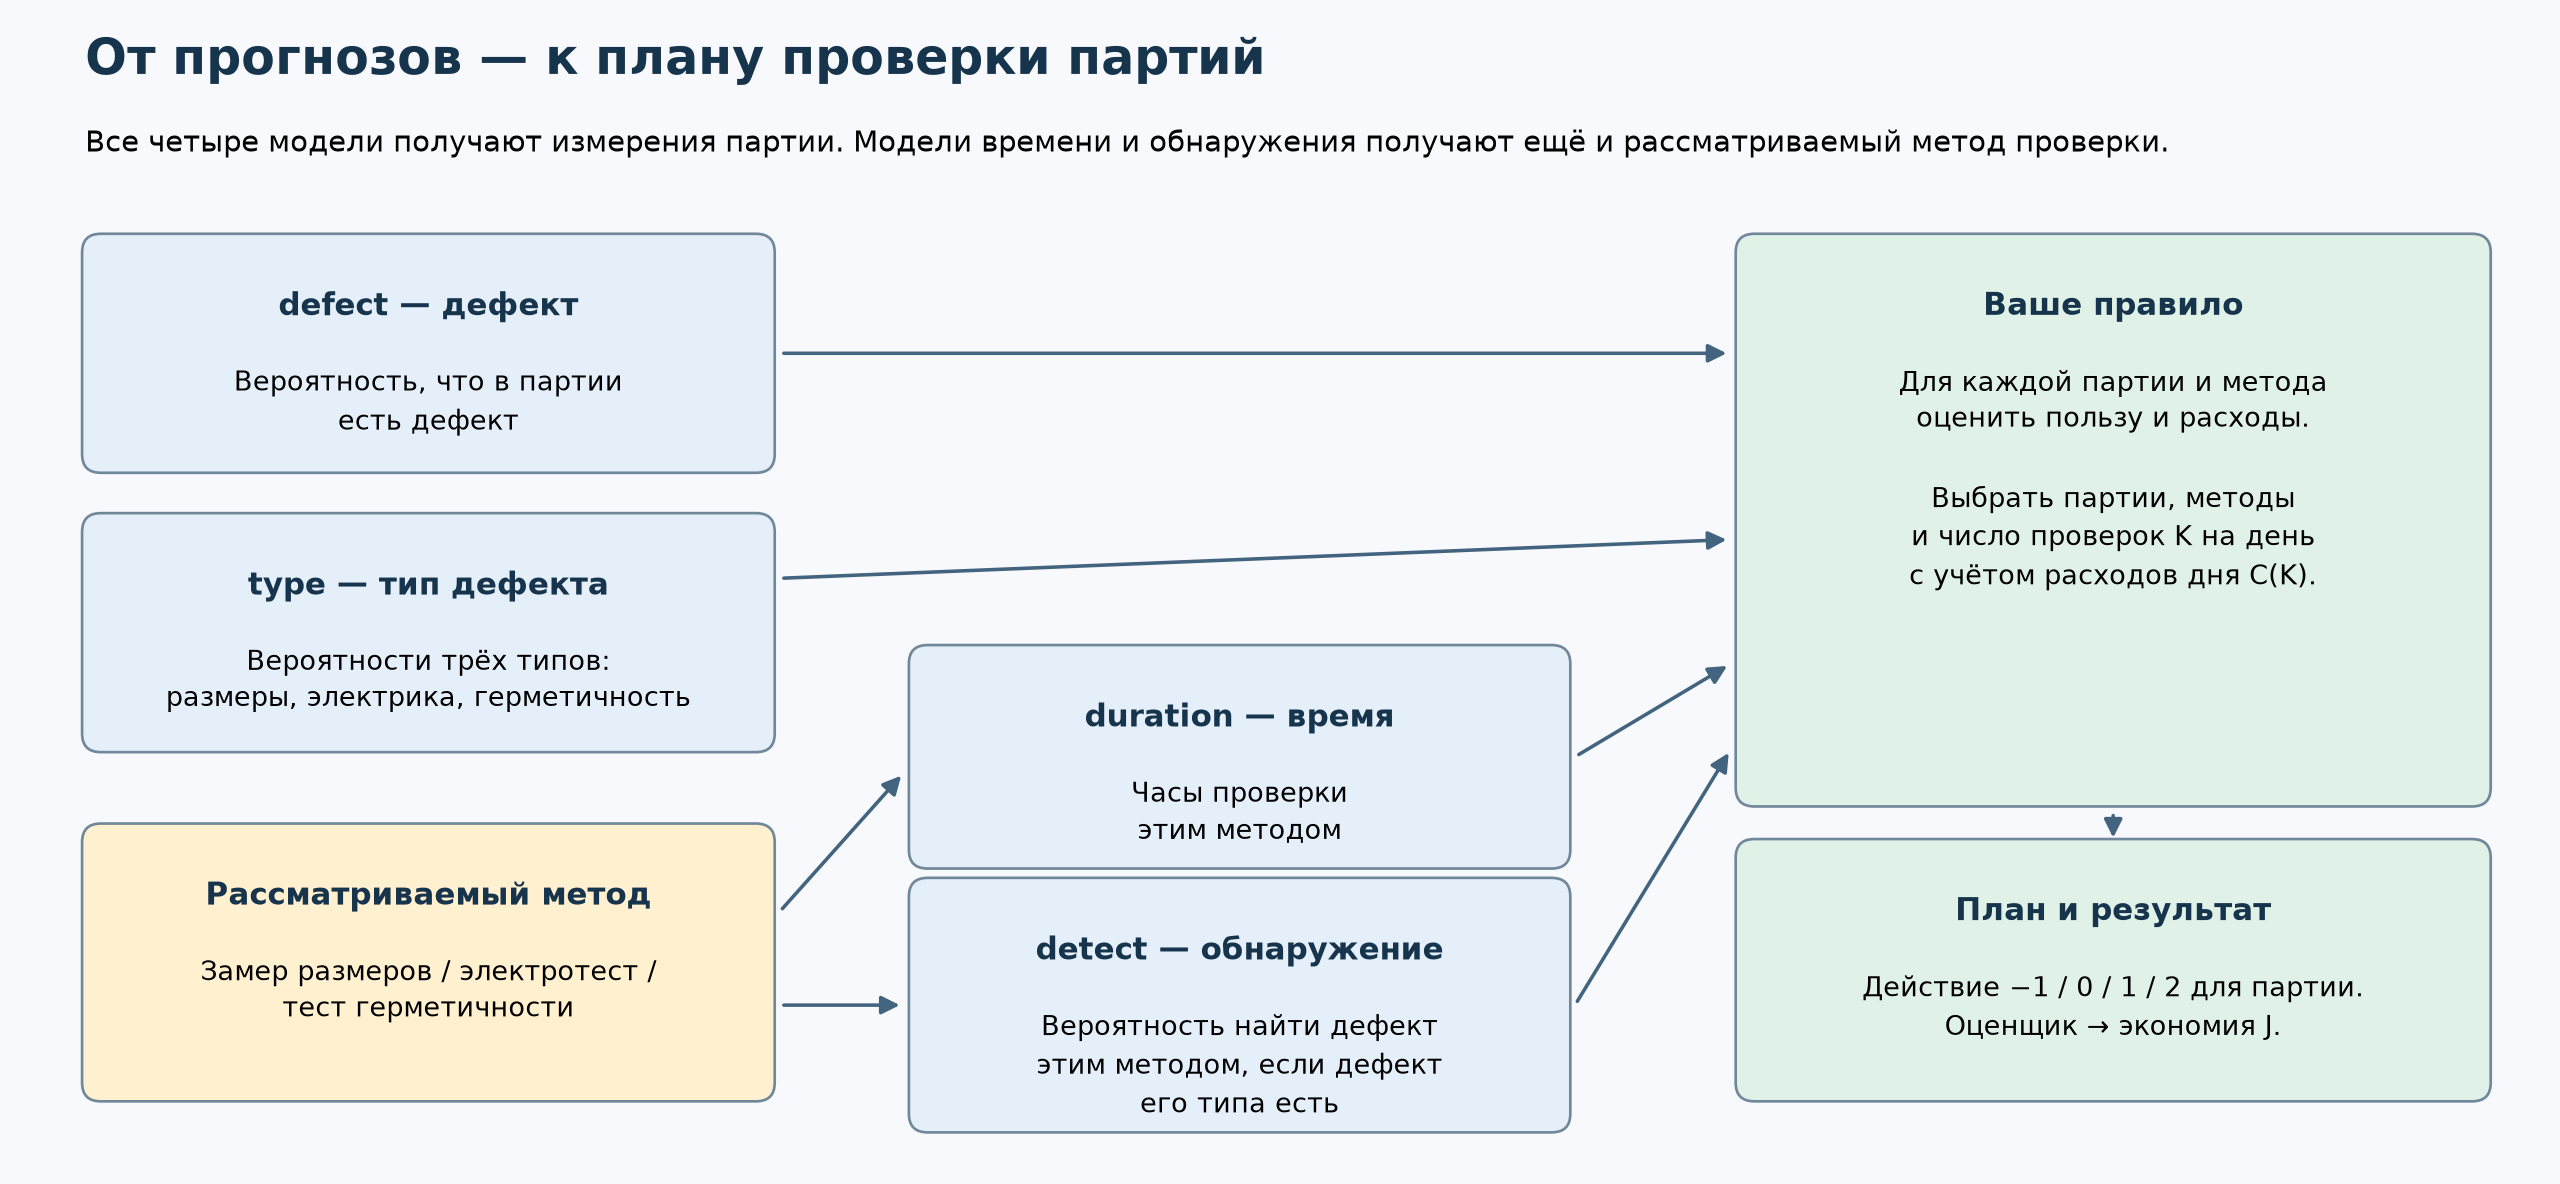

## Справочник данных и функций

Этот раздел поясняет файлы, поля и инструменты. Все обязательные требования находятся в условии.

| Файл | Для чего он нужен |
|---|---|
| `validation_features.csv` | Открытые измерения: 120 дней, 7 200 партий. Здесь разрабатывайте и проверяйте правило |
| `validation_labels.csv` | Результаты полного аудита открытых партий: ответы для метрик моделей |
| `validation_outcomes.csv` | Ожидаемые последствия проверки каждой партии каждым методом: по ним оценщик считает J |
| `test_features.csv` | Измерения для итогового решения: 480 дней, 28 800 партий. Ответов здесь нет |
| `models.json` | 12 готовых моделей с карточками |
| `hw3_runtime.py` | Загрузка моделей, проверка действий, расчёт экономики и оформление графиков |
| `baselines.csv` | Результаты простых правил на открытых данных |

Измерения доступны **до** решения. `batch_id` — идентификатор партии, `day` — номер дня,
`batch_value_rub` — стоимость партии, рубли. Остальные признаки:

| Признак | Смысл |
|---|---|
| `supplier_score` | Рейтинг качества поставщика комплектующих, от 0 до 1 (больше — лучше) |
| `tool_wear` | Износ оснастки линии, от 0 до 1 |
| `solder_temp_dev` | Отклонение температуры пайки от нормы, от 0 до 1 |
| `humidity` | Влажность в цехе, от 0 до 1 |
| `seal_pressure_dev` | Отклонение давления при запайке корпуса, от 0 до 1 |
| `night_shift` | Партия выпущена ночной сменой: 1 — да, 0 — нет |
| `new_product` | Изделие выпускается первый месяц: 1 — да, 0 — нет |
| `batch_size` | Число изделий в партии, штуки |
| `complexity` | Сложность изделия, от 0 до 1 |
| `inline_alarms` | Число сигналов датчиков линии при выпуске партии |

В файле ответов `validation_labels.csv` (результаты полного аудита):

| Поле | Что наблюдали |
|---|---|
| `defect` | Был ли в партии дефект: 1 — да, 0 — нет |
| `defect_type` | Тип дефекта: 0 — размеры, 1 — электрика, 2 — герметичность; пусто, если дефекта нет |
| `hours_0`, `hours_1`, `hours_2` | Сколько часов заняла проверка методом 0, 1, 2 |
| `found_0`, `found_1`, `found_2` | Нашёл ли дефект метод 0, 1, 2: 1 — да, 0 — нет; пусто, если дефекта нет |

Метод 0 подходит для типа 0, метод 1 — для типа 1, метод 2 — для типа 2.

В файле `validation_outcomes.csv` одна строка на партию и метод (`action` 0, 1, 2):
`prevented` — ожидаемые предотвращённые потери в рублях, `hours` — среднее время проверки
в часах. Это средние последствия многократного повторения ситуации, известные генератору;
они уменьшают влияние удачи одной проверки на соревнование. Повторно умножать
`prevented` на вероятность дефекта не нужно.

### Модели

`load_models(path)` возвращает словарь `models[task][name]`: задача `defect`, `type`,
`duration` или `detect`, вариант `M1`, `M2` или `M3`. У каждой модели есть поля
`spec["algorithm"]` (алгоритм), `spec["training_parameters"]` (параметры обучения scikit-learn)
и `note` (карточка: кратко, как модель обучена).

- `models["defect"][name].predict_proba(features)` — массив формы (n, 2); столбец 1 — вероятность дефекта.
- `models["type"][name].predict_proba(features)` — массив формы (n, 3): вероятности типов 0, 1, 2.
- `models["duration"][name].predict(features, method=m)` — часы проверки методом m.
- `models["detect"][name].predict_proba(features, method=m)` — массив (n, 2); столбец 1 — вероятность,
  что метод m найдёт дефект, если в партии дефект типа m.

`method` — одно число 0, 1, 2 для всех строк или массив кодов длиной в число строк.
Модель `type` обучена только на партиях с дефектом, модель `detect` — только на партиях
с дефектом, проверенных подходящим методом.

### Готовые инструменты

- `baseline_actions(features, models, kind, k)` — простые правила с моделями M1: `none` — не проверять;
  `defect` — первые k партий дня по вероятности дефекта; `defect_value` — по произведению вероятности
  дефекта и стоимости партии. Метод — самый вероятный тип.
- `validate_actions(features, actions)` — проверяет формат и дневной лимит.
- `evaluate(features, outcomes, actions)` — возвращает словарь итогов и таблицу по дням
  (`k`, `prevented`, `consumables`, `labor`, `overload` — дневная надбавка C(K), `effect` — экономия J за день);
  `effect_per_day` — средняя экономия за день.
- `plot_economics(daily)`, `plot_metric_table(table, pairs)` — оформление графиков.
- `overload_cost(k)` — C(K); `METHOD_COST` — расходные материалы методов 0/1/2; `LABOR_PER_HOUR` — 1 800 руб.;
  `LOSS_MULTIPLIER` — коэффициенты потерь типов 0/1/2; `K_MAX` — 24.
- `stability_score(strategy_daily, baseline_daily, seed=42)` — сравнивает дневную экономию правила с базовым
  правилом `baseline_actions(features, models, kind="defect_value", k=6)`; подробно — в условии.

## Данные и модели

Ячейка ниже находит или скачивает файлы задания (около 8 МБ) в папку `hw3_data`,
загружает данные и 12 моделей и печатает карточку каждой модели.
Используйте последние версии numpy, pandas, scikit-learn и matplotlib. Ячейка
не устанавливает пакеты: если какого-то нет, она остановится и напишет команду
установки. Модели применяются через numpy; версия scikit-learn при их обучении
не влияет на загрузку JSON.

In [ ]:
## ── пакеты: проверка, что всё установлено ─────────────────────────
from pathlib import Path
import os
import sys
import importlib.util
import urllib.request

missing = [package for module, package in
           [("numpy", "numpy"), ("pandas", "pandas"),
            ("matplotlib", "matplotlib"), ("sklearn", "scikit-learn")]
           if importlib.util.find_spec(module) is None]
if missing:
    raise RuntimeError(f"Установите последние версии пакетов: python -m pip install -U {' '.join(missing)}")

## ── данные: рядом с ноутбуком или из репозитория курса ─────────────
DATA_FILES = ['models.json', 'hw3_runtime.py', 'baselines.csv', 'validation_features.csv', 'validation_labels.csv', 'validation_outcomes.csv', 'test_features.csv']
DATA_URL = os.environ.get("HW3_DATA_URL", "https://raw.githubusercontent.com/Rimest/ml_ai_course_gsb_hse/main/homeworks/hw3_quality_control")
candidates = [Path("."), Path("hw3_data"), Path("homeworks/hw3_quality_control"), Path("../student")]
DATA_DIR = next((p.resolve() for p in candidates
                 if all((p / name).exists() for name in DATA_FILES)), None)
if DATA_DIR is None:
    DATA_DIR = Path("hw3_data").resolve()
    DATA_DIR.mkdir(exist_ok=True)
    for name in DATA_FILES:
        print(f"Скачиваю {name}")
        urllib.request.urlretrieve(f"{DATA_URL}/{name}", DATA_DIR / name)
sys.path.insert(0, str(DATA_DIR))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(SEED)
from hw3_runtime import (load_models, validate_actions, evaluate, baseline_actions,
    plot_economics, plot_metric_table, stability_score, overload_cost, K_MAX,
    METHOD_COST, LABOR_PER_HOUR, LOSS_MULTIPLIER, FEATURES, TASKS, TYPE_NAMES,
    METHOD_NAMES, ID)

models = load_models(DATA_DIR / "models.json")
validation = pd.read_csv(DATA_DIR / "validation_features.csv")
labels = pd.read_csv(DATA_DIR / "validation_labels.csv")
outcomes = pd.read_csv(DATA_DIR / "validation_outcomes.csv")
test = pd.read_csv(DATA_DIR / "test_features.csv")
assert validation[ID].equals(labels[ID])

def check(ok, message):
    if not ok:
        raise AssertionError(message)
    print("✓ верно")

print(f"Открытые данные: {len(validation)} партий; тест: {len(test)}")
for task, variants in models.items():
    for name, model in variants.items():
        print(f"{task:<9} {name}  {model.spec['algorithm']:<27} {model.note}")

In [ ]:
print(validation.head(3).to_string(index=False))
print(labels.head(3).to_string(index=False))
print(f"Доля партий с дефектом: {labels.defect.mean():.3f}")
types = labels.defect_type.dropna().astype(int).value_counts().sort_index()
for code, count in types.items():
    print(f"{TYPE_NAMES[code]:<14} {count:>5} партий")
example = validation.iloc[:3]
print(f"Вероятность дефекта, M1: {models['defect']['M1'].predict_proba(example)[:, 1].round(3)}")
print(f"Вероятности типов, M1:\n{models['type']['M1'].predict_proba(example).round(3)}")
print(f"Часы электротеста, M1: {models['duration']['M1'].predict(example, method=1).round(2)}")
print(f"Обнаружение электротестом, M1: {models['detect']['M1'].predict_proba(example, method=1)[:, 1].round(3)}")

Простые правила с моделями M1 показывают масштаб чисел. Для каждого правила
печатаются два поля словаря итогов `evaluate`: `effect_per_day` — средняя
экономия за день, руб., `mean_k` — среднее число проверок в день.

In [ ]:
baseline_rows = []
for kind in ("none", "defect", "defect_value"):
    result, daily = evaluate(validation, outcomes, baseline_actions(validation, models, kind=kind, k=6))
    baseline_rows.append({"strategy": kind, **result})
baselines = pd.DataFrame(baseline_rows)
print(baselines[["strategy", "effect_per_day", "mean_k"]].to_string(index=False))
plot_economics(daily)
plt.show()
check(baselines.loc[baselines.strategy == "none", "effect_per_day"].iloc[0] == 0,
      "Без проверок экономия должна быть нулевой")

## Решение

Ноутбук должен ответить на четыре вопроса условия:

1. Какой вариант вы используете для каждой из четырёх задач и почему? Какими метриками подтверждён выбор и как он сказывается на J?
2. Насколько каждая модель нужна вашему решению?
3. Как вы выбираете число проверок K?
4. Насколько результат устойчив на контрольных днях?

### Задание 1. Выберите контрольные дни (часть 3 условия)

Разделите 120 открытых дней на дни разработки и контрольные дни до любой
настройки. Запишите номера контрольных дней в список целых чисел
`control_days`. Объясните выбор в текстовой ячейке после проверки. Все
последующие выборы моделей и параметров делайте по дням разработки.

In [ ]:
control_days = ...  # TODO
raise NotImplementedError("Выполните задание и замените эту строку")

In [ ]:
check(isinstance(control_days, list) and all(isinstance(d, (int, np.integer)) for d in control_days),
      "control_days — список целых номеров дней")
check(2 <= len(set(control_days)) < validation.day.nunique() and set(control_days) <= set(validation.day),
      "Контрольные дни — не меньше двух открытых дней, но не все открытые дни")
development = validation.loc[~validation.day.isin(control_days)].reset_index(drop=True)
development_labels = labels.loc[~validation.day.isin(control_days)].reset_index(drop=True)
development_outcomes = outcomes.loc[outcomes[ID].isin(development[ID])]
print(f"Разработка: {development.day.nunique()} дней; контроль: {len(set(control_days))} дней")

**Почему такие контрольные дни:** ...

### Задание 2. Зафиксируйте правило (часть 1 условия)

Реализуйте `strategy(features, models)`: она получает таблицу признаков любых
дней и словарь моделей и возвращает DataFrame со столбцами `batch_id,action`
для всех строк. Используйте только признаки, прогнозы моделей и ваши общие
параметры. Перед функцией запишите выбранные варианты моделей и параметры.

In [ ]:
def strategy(features, models):
    ...  # TODO
raise NotImplementedError("Выполните задание и замените эту строку")

In [ ]:
validation_actions = strategy(validation, models)
check(len(validate_actions(validation, validation_actions)) == len(validation), "strategy должна вернуть действие для каждой партии")
for part, mask in [("разработка", ~validation.day.isin(control_days)), ("контроль", validation.day.isin(control_days))]:
    f = validation.loc[mask].reset_index(drop=True)
    result, _ = evaluate(f, outcomes[outcomes[ID].isin(f[ID])], validation_actions[validation_actions[ID].isin(f[ID])])
    money = f"{result['effect_per_day']:>10,.0f}".replace(",", " ")
    print(f"{part:<11} {money} руб./день; K в среднем {result['mean_k']:.2f}")

**Ваш анализ.** Добавьте ниже ячейки с расчётами, графиками и выводами, отвечающими на четыре вопроса.

In [ ]:
# Ваши расчёты

## Устойчивость относительно базового правила

`stability_score(strategy_daily, baseline_daily, seed=42)` получает две дневные
таблицы из `evaluate` на одних и тех же днях (индекс — день, `effect` — экономия
за день) и возвращает одно число в рублях за день: 5-й процентиль средних
разностей по 10 000 выборкам дней с возвращением. Положительное значение
подтверждает преимущество над базовым правилом; отрицательное — преимущество
не подтверждено, правило может оказаться и хуже базового. Метод предполагает
независимость дней и менее надёжен при малом числе дней. Ячейка использует
`control_days`.

In [ ]:
control_features = validation.loc[validation.day.isin(control_days)].reset_index(drop=True)
control_outcomes = outcomes.loc[outcomes[ID].isin(control_features[ID])]
_, strategy_daily = evaluate(control_features, control_outcomes, strategy(control_features, models))
_, baseline_daily = evaluate(control_features, control_outcomes,
    baseline_actions(control_features, models, kind="defect_value", k=6))
stability = stability_score(strategy_daily, baseline_daily, seed=42)
money = f"{stability:,.2f}".replace(",", " ").replace(".", ",")
print(f"Нижняя граница среднего преимущества: {money} руб./день")

## Файл сдачи

Ячейка ниже собирает `ФАМИЛИЯ_ИО_actions.csv`. Формат одинаков у всех,
поэтому код готовый — выполните ячейку, менять её не требуется. К этому
моменту должны быть определены:

| Имя | Что это |
|---|---|
| `STUDENT_NAME` | фамилия и инициалы из преамбулы |
| `strategy` | ваше правило из задания 2 |
| `test` | признаки партий закрытого теста, загружены выше |

Получится файл с двумя столбцами — по строке на каждую из 28 800 партий
закрытого теста, включая непроверяемые (−1):

```
batch_id,action
test_000000,-1
test_000001,2
```

Проверка формата не подтверждает выгоду.

In [ ]:
## ── файл сдачи ─────────────────────────────────────────────────────
check(STUDENT_NAME != "ФАМИЛИЯ_ИО", "Впишите фамилию и инициалы в STUDENT_NAME в преамбуле")
test_actions = validate_actions(test, strategy(test, models))
submission_path = f"{STUDENT_NAME}_actions.csv"
test_actions.to_csv(submission_path, index=False, encoding="utf-8")

## ── проверка перед сдачей ──────────────────────────────────────────
check(len(test_actions) == len(test), "Нужны действия для всех партий теста")
mean_k = (test_actions.action >= 0).sum() / test.day.nunique()
print(f"Сохранён {submission_path}: {len(test_actions)} строк; проверок в среднем {mean_k:.2f} в день")

## Как оценивается работа

За работу — до 10 баллов.

| За что | Баллов | Как считается |
|---|---|---|
| Экономика | 4 | по месту в рейтинге по J за 480 дней закрытого теста; участвуют решения, которые сэкономили хотя бы на 480 000 руб. больше базового правила |
| Анализ | 4 | полнота и корректность ответов на четыре вопроса; балл не зависит от места в рейтинге |
| Воспроизводимость и объяснение | 2 | ноутбук запускается сверху вниз и воспроизводит файл сдачи, правило и параметры понятны, история выбора описана, есть описание использования ИИ |

Порог и перевод места в баллы — в условии. При нарушении
раздела «Ограничения» условия за экономику ставится 0.

## Использование ИИ

Опишите в следующей ячейке, как вы использовали ИИ: инструмент, цель,
существенные подсказки, принятые предложения и способ проверки. Если ИИ
не использовали, так и напишите.

**Использование ИИ:** ...